# Notebook 2. One storm, three estimates

**Predicting Flash Floods in Working Landscapes**, Module 1, Quantitative Precipitation Estimation (QPE)
CUAHSI Water Science Exchange 2026, University of Missouri, Saturday November 14, 2026
Mohamed Abdelkader, Humberto Vergara and Santiago Henao Gomez, University of Iowa, IIHR and Iowa Flood Center

## The event

On the night of June 21 to 22, 2024, a line of thunderstorms trained over northwest Iowa, southeast South Dakota and southwest Minnesota. Totals above 150 mm fell in a few hours on soils already wet from several days of rain.

- The National Weather Service in Sioux Falls issued a Flash Flood Emergency for Rock Valley, Iowa, at 1:56 am CDT on June 22 after a levee on the Rock River failed.
- The Rock River near Rock Valley (USGS 06483500) peaked at 157,000 cubic feet per second, the highest flow in 127 years of record.
- The Floyd River at Alton (USGS 06600100) peaked at 41,000 cubic feet per second, the highest since 1953.

This is the storm that drives the simulation in Module 2 and the evaluation in Module 3. Today we ask a simpler question. How much rain fell, where, and how well did we know it while it was happening?

## Objective of this notebook

Evaluate radar-only and gauge-corrected rainfall estimates against gauges for a flash flood event (Module objective 4), and quantify what a forecaster could have known at the time.

| Step | What we do |
|---|---|
| 1 | Download 24 hours of MRMS radar only, Pass 1 and Pass 2 for the storm |
| 2 | Compare the three products for the peak hour |
| 3 | Map where the gauges changed the estimate |
| 4 | Build storm totals and compare them |
| 5 | Check the products against hourly gauges |
| 6 | Check the storm totals against independent volunteer gauges |
| 7 | Average the rainfall over a river basin, the input of Module 2 |
| 8 | Guided activity, the forecaster at 6 am |

## 0. Setup

In [1]:
# Run once per session. Remove the leading # if you are missing packages.
# %pip install -q numpy pandas xarray netcdf4 h5netcdf h5py eccodes cfgrib s3fs requests matplotlib cartopy pyproj scipy shapely

In [2]:
import warnings; warnings.filterwarnings("ignore")
import time
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from qpe_tools import *

plt.rcParams.update({"font.size": 12, "axes.titlesize": 13, "text.color": "black",
                     "axes.labelcolor": "black", "xtick.color": "black", "ytick.color": "black"})

# The study box, west, east, south, north. It holds the Rock and Floyd river basins.
EVENT_BOX = (-97.5, -94.5, 42.0, 44.5)

# 24 hourly files, stamped with the END of each hour. The window matches the CoCoRaHS morning reading.
HOURS = pd.date_range("2024-06-21 13:00", "2024-06-22 12:00", freq="h")
T0, T1 = HOURS[0] - pd.Timedelta(hours=1), HOURS[-1]          # start and end of the 24 h window

PRODUCTS = ["RadarOnly", "Pass1", "Pass2"]
STYLE = {"RadarOnly": dict(color="black", linestyle=":"),
         "Pass1": dict(color="black", linestyle="--"),
         "Pass2": dict(color="black", linestyle="-")}

# Two places we refer to on the maps.
ROCK_VALLEY = (-96.295, 43.205)
ALTON = (-96.010, 42.987)

print(f"{len(HOURS)} hours from {T0} to {T1} UTC")

24 hours from 2024-06-21 12:00:00 to 2024-06-22 12:00:00 UTC


## 1. Download the three hourly products

Three products, 24 hours each, 72 files of about 1 MB. The helper clips every file to the box and stores the result in `data/cache`, so the second run is instant. If the repository came with a filled cache, nothing is downloaded.

In [3]:
t_start = time.time()
hourly = {p: read_mrms_series(p, HOURS, EVENT_BOX, verbose=False) for p in PRODUCTS}
print(f"done in {time.time() - t_start:.0f} s")

for p in PRODUCTS:
    da = hourly[p]
    print(f"{LABELS[p]:22s} shape {da.shape}   largest hourly value {float(da.max()):5.1f} mm")

done in 1 s
Radar only             shape (24, 250, 300)   largest hourly value  82.8 mm
Multi-sensor Pass 1    shape (24, 250, 300)   largest hourly value  71.3 mm
Multi-sensor Pass 2    shape (24, 250, 300)   largest hourly value  69.1 mm


The result for each product is a 3-D array, time by latitude by longitude. Let us look at one.

In [4]:
hourly["Pass2"]

<xarray.DataArray 'Pass2' (time: 24, lat: 250, lon: 300)> Size: 7MB
array([[[0. , 0. , 0. , ..., 0.5, 0.5, 0.6],
        [0. , 0. , 0. , ..., 0.5, 0.6, 0.7],
        [0. , 0. , 0. , ..., 0.7, 0.8, 0.9],
        ...,
        [0. , 0. , 0. , ..., 0. , 0. , 0. ],
        [0. , 0. , 0. , ..., 0. , 0. , 0. ],
        [0. , 0. , 0. , ..., 0. , 0. , 0. ]],

       [[0. , 0. , 0. , ..., 0. , 0. , 0. ],
        [0. , 0. , 0. , ..., 0. , 0. , 0. ],
        [0. , 0. , 0. , ..., 0. , 0. , 0. ],
        ...,
        [0. , 0. , 0. , ..., 0. , 0. , 0. ],
        [0. , 0. , 0. , ..., 0. , 0. , 0. ],
        [0. , 0. , 0. , ..., 0. , 0. , 0. ]],

       [[0. , 0. , 0. , ..., 0. , 0. , 0. ],
        [0. , 0. , 0. , ..., 0. , 0. , 0. ],
        [0. , 0. , 0. , ..., 0. , 0. , 0. ],
        ...,
...
        [0. , 0. , 0. , ..., 0.4, 0.4, 0.3],
        [0. , 0. , 0. , ..., 0.3, 0.4, 0.3],
        [0. , 0. , 0. , ..., 0.3, 0.3, 0.3]],

       [[0. , 0. , 0. , ..., 0. , 0. , 0. ],
        [0. , 0. , 0. , ..., 0. , 0. , 0. ],
        [0. , 0. , 0. , ..., 0. , 0. , 0. ],
        ...,
        [0. , 0. , 0. , ..., 0. , 0. , 0. ],
        [0. , 0. , 0. , ..., 0. , 0. , 0. ],
        [0. , 0. , 0. , ..., 0. , 0. , 0. ]],

       [[0. , 0. , 0. , ..., 0. , 0. , 0. ],
        [0. , 0. , 0. , ..., 0. , 0. , 0. ],
        [0. , 0. , 0. , ..., 0. , 0. , 0. ],
        ...,
        [0. , 0. , 0. , ..., 0. , 0. , 0. ],
        [0. , 0. , 0. , ..., 0. , 0. , 0. ],
        [0. , 0. , 0. , ..., 0. , 0. , 0. ]]],
      shape=(24, 250, 300), dtype=float32)
Coordinates:
  * time     (time) datetime64[us] 192B 2024-06-21T13:00:00 ... 2024-06-22T12...
  * lat      (lat) float64 2kB 44.49 44.48 44.47 44.46 ... 42.02 42.02 42.0
  * lon      (lon) float64 2kB -97.5 -97.49 -97.48 ... -94.52 -94.51 -94.5
Attributes:
    valid_time:  2024-06-21T13:00:00+00:00
    product:     Pass2
    source:      aws
    units:       mm
    long_name:   Multi-sensor Pass 2

## 2. One hour, three ways

The heaviest hour over the Rock River basin ended at 04:00 UTC (11 pm CDT). Same hour, same colour scale, three products.

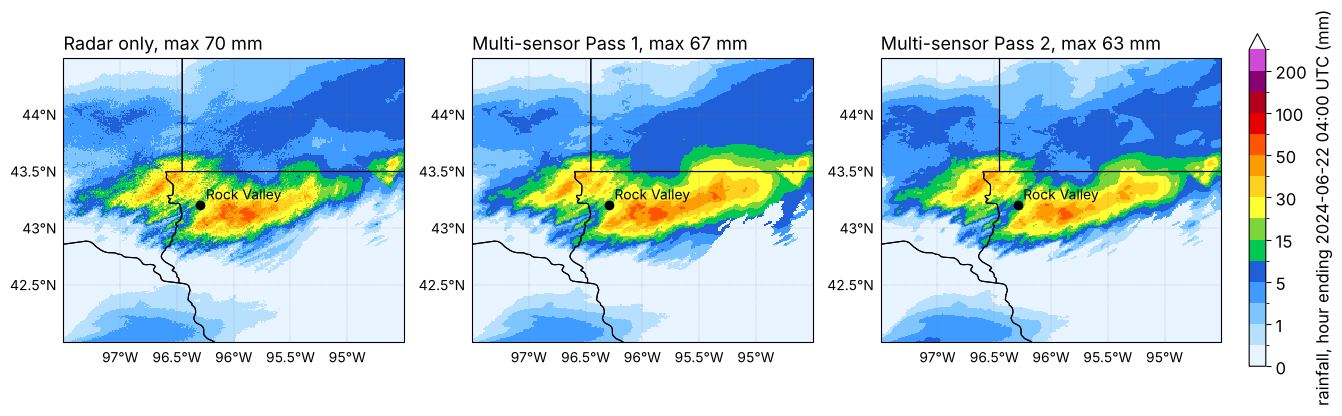

In [5]:
PEAK = "2024-06-22 04:00"

fig, axes = plt.subplots(1, 3, figsize=(18, 5.4), subplot_kw={"projection": ccrs.PlateCarree()})
for ax, p in zip(axes, PRODUCTS):
    field = hourly[p].sel(time=PEAK)
    mesh = rain_map(field, EVENT_BOX, f"{LABELS[p]}, max {float(field.max()):.0f} mm", ax=ax)
    ax.plot(*ROCK_VALLEY, marker="o", color="black", markersize=6, transform=ccrs.PlateCarree())
    ax.text(ROCK_VALLEY[0] + 0.05, ROCK_VALLEY[1] + 0.05, "Rock Valley", fontsize=10)
fig.colorbar(mesh, ax=axes, shrink=0.8, pad=0.02, label=f"rainfall, hour ending {PEAK} UTC (mm)")
plt.show()

At a glance the three maps are alike. The storm shape comes from the radar in all of them. The gauges change the amounts, and that is what matters for a flood. Difference maps make the change visible.

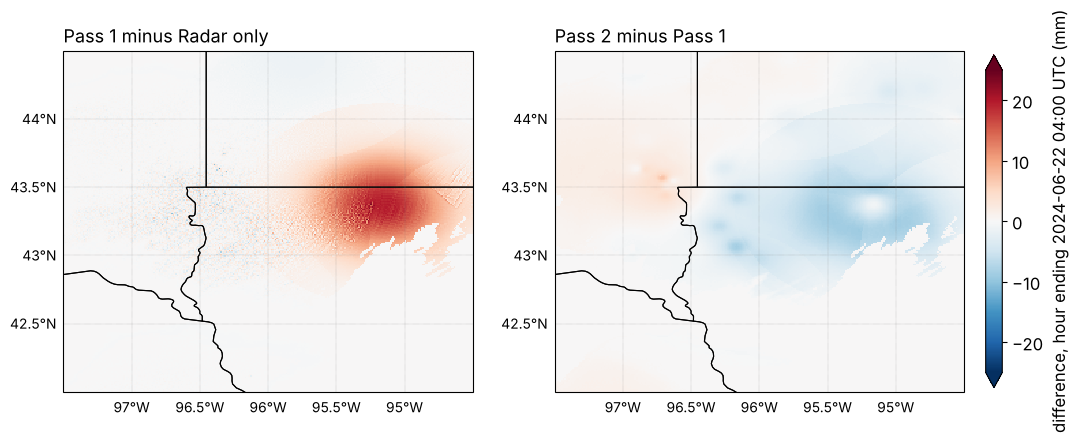

In [6]:
step1 = hourly["Pass1"].sel(time=PEAK) - hourly["RadarOnly"].sel(time=PEAK)    # what the first gauges did
step2 = hourly["Pass2"].sel(time=PEAK) - hourly["Pass1"].sel(time=PEAK)        # what the later gauges did

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), subplot_kw={"projection": ccrs.PlateCarree()})
for ax, field, title in zip(axes, [step1, step2], ["Pass 1 minus Radar only", "Pass 2 minus Pass 1"]):
    mesh = ax.pcolormesh(field.lon, field.lat, field, cmap="RdBu_r", vmin=-25, vmax=25,
                         transform=ccrs.PlateCarree(), shading="auto")
    add_map_features(ax, EVENT_BOX)
    ax.set_title(title, loc="left")
fig.colorbar(mesh, ax=axes, shrink=0.8, pad=0.02, extend="both", label=f"difference, hour ending {PEAK} UTC (mm)")
plt.show()

Red means the later product is wetter, blue means drier. The corrections are local, a few tens of kilometres wide, and they follow the gauge locations.

## 3. Where did the gauges act

MRMS publishes a **gauge influence index** with every multi-sensor product. It is 0 where the estimate is pure radar and 1 where it is fully pulled to a gauge. It is the honest answer to "did a gauge touch this pixel".

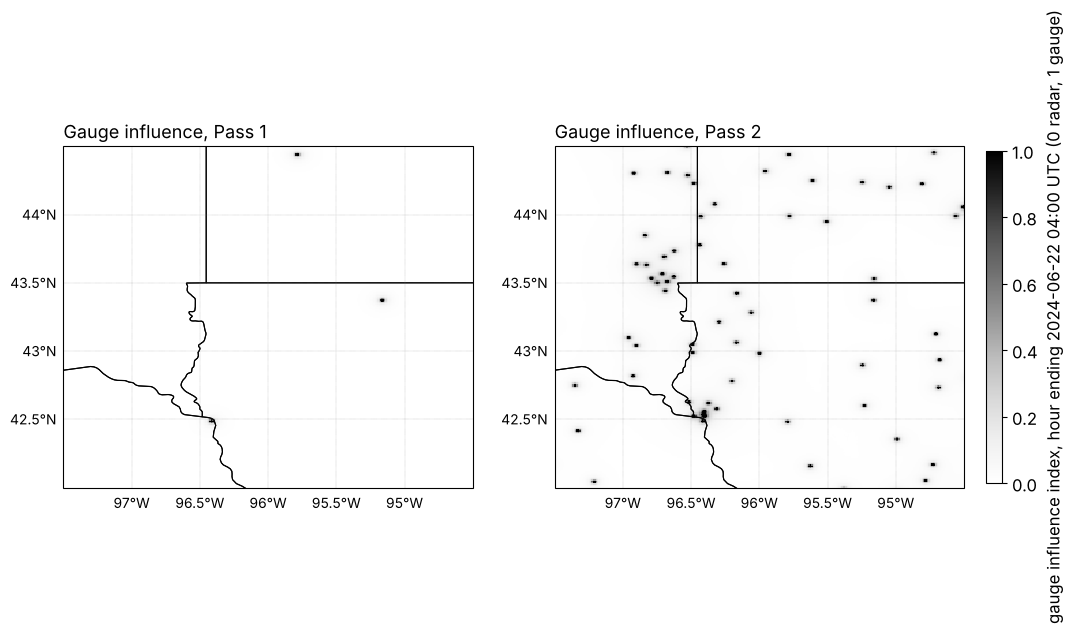

In [7]:
gii = {p: read_mrms_series(p, HOURS, EVENT_BOX, verbose=False) for p in ["GII_Pass1", "GII_Pass2"]}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), subplot_kw={"projection": ccrs.PlateCarree()})
for ax, p in zip(axes, ["GII_Pass1", "GII_Pass2"]):
    field = gii[p].sel(time=PEAK)
    mesh = ax.pcolormesh(field.lon, field.lat, field, cmap="Greys", vmin=0, vmax=1,
                         transform=ccrs.PlateCarree(), shading="auto")
    add_map_features(ax, EVENT_BOX)
    ax.set_title(LABELS[p], loc="left")
fig.colorbar(mesh, ax=axes, shrink=0.8, pad=0.02, label=f"gauge influence index, hour ending {PEAK} UTC (0 radar, 1 gauge)")
plt.show()

Pass 2 has more dark spots than Pass 1. Those are the gauges that reported late. Count them.

In [8]:
for p in ["GII_Pass1", "GII_Pass2"]:
    influenced = float((gii[p].sel(time=PEAK) > 0.5).sum())          # cells mostly set by a gauge
    print(f"{LABELS[p]:28s} {influenced:6.0f} cells with index above 0.5")

Gauge influence, Pass 1          23 cells with index above 0.5
Gauge influence, Pass 2         489 cells with index above 0.5


## 4. Storm totals

Add the 24 hourly fields. Missing cells count as zero.

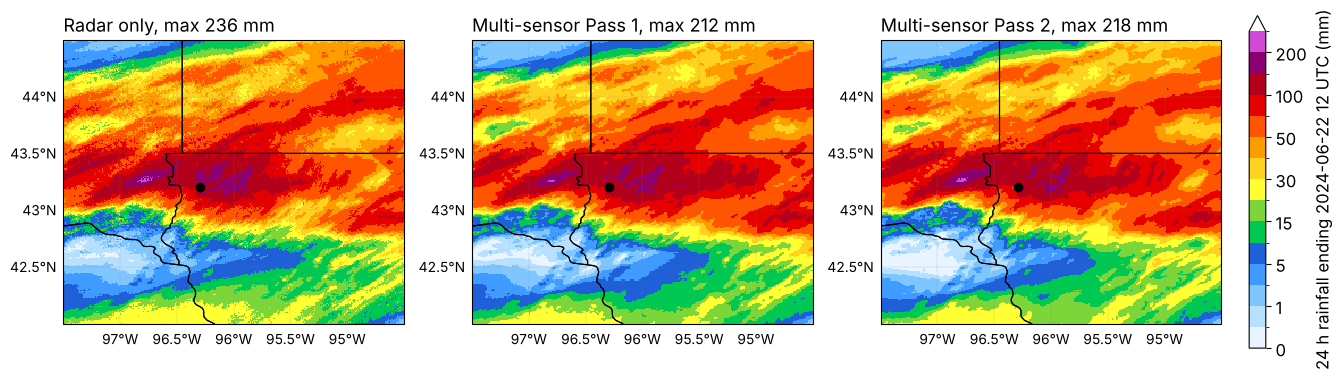

In [9]:
total = {p: hourly[p].fillna(0).sum(dim="time") for p in PRODUCTS}

fig, axes = plt.subplots(1, 3, figsize=(18, 5.4), subplot_kw={"projection": ccrs.PlateCarree()})
for ax, p in zip(axes, PRODUCTS):
    mesh = rain_map(total[p], EVENT_BOX, f"{LABELS[p]}, max {float(total[p].max()):.0f} mm", ax=ax)
    ax.plot(*ROCK_VALLEY, marker="o", color="black", markersize=6, transform=ccrs.PlateCarree())
fig.colorbar(mesh, ax=axes, shrink=0.8, pad=0.02, label="24 h rainfall ending 2024-06-22 12 UTC (mm)")
plt.show()

In [10]:
# How much did the gauges change the storm total over the whole box?
for p in ["Pass1", "Pass2"]:
    change = float((total[p] - total["RadarOnly"]).mean())
    ratio = float(total[p].sum() / total["RadarOnly"].sum())
    print(f"{LABELS[p]:22s} mean change {change:+5.1f} mm   volume ratio to radar only {ratio:.2f}")

Multi-sensor Pass 1    mean change  +1.0 mm   volume ratio to radar only 1.02
Multi-sensor Pass 2    mean change  -0.2 mm   volume ratio to radar only 1.00


A check on our arithmetic. MRMS also publishes a ready-made 24 h Pass 2 total. Our sum of 24 hourly files should match it closely. Small differences come from the rounding of each hourly file.

In [11]:
official = read_mrms("Pass2_24", T1, EVENT_BOX)
diff = total["Pass2"] - official.fillna(0)
print(f"sum of hourly files vs official 24 h product: mean difference {float(diff.mean()):+.2f} mm, "
      f"largest absolute difference {float(abs(diff).max()):.1f} mm")

sum of hourly files vs official 24 h product: mean difference +0.00 mm, largest absolute difference 0.0 mm


## 5. Hourly gauges

We gather every hourly gauge inside the box from three networks. Each helper returns the same columns, so one table holds them all.

In [12]:
# ISU Soil Moisture Network, tipping buckets at research farms.
isusm_sites = iem_stations("ISUSM", EVENT_BOX)
isusm = load_or_fetch("isusm_event.csv", lambda: iem_isusm_hourly(isusm_sites.station, T0, T1))
isusm = isusm.merge(isusm_sites[["station", "lon", "lat"]], on="station")

# Airports in four states.
asos_sites = pd.concat([iem_stations(n, EVENT_BOX) for n in ["IA_ASOS", "SD_ASOS", "MN_ASOS", "NE_ASOS"]])
asos = load_or_fetch("asos_event.csv", lambda: iem_asos_hourly(asos_sites.station, T0, T1))

# NOAA Climate Reference Network, one station in the box.
crn = load_or_fetch("uscrn_event.csv", lambda: uscrn_hourly("SD_Sioux_Falls_14_NNE", 2024, T0, T1))

gauges = pd.concat([isusm, asos, crn], ignore_index=True)
print(len(gauges), "hourly records from", gauges.station.nunique(), "stations")

690 hourly records from 29 stations


Quality check first. An airport that reports zero through a 150 mm storm has no working sensor. We drop those stations.

In [13]:
totals = gauges.groupby(["station", "network"], as_index=False).agg(total_mm=("mm", "sum"), hours=("mm", "size"),
                                                                     lon=("lon", "first"), lat=("lat", "first"))
dead = totals[(totals.network == "ASOS") & (totals.total_mm == 0)].station.tolist()
print("dropped, zero total during the storm:", dead)

gauges = gauges[~gauges.station.isin(dead)]
totals = totals[~totals.station.isin(dead)].sort_values("total_mm", ascending=False).reset_index(drop=True)
totals

dropped, zero total during the storm: ['LRJ', 'LYV', 'MDS']


,station,network,total_mm,hours,lon,lat
0,CSII4,ISUSM,121.40946,24,-96.504251,43.310471
1,JYG,ASOS,87.37600,24,-94.557900,43.986300
2,EST,ASOS,85.86216,24,-94.747600,43.400800
3,DONI4,ISUSM,85.59800,24,-96.187520,43.298802
4,SPW,ASOS,78.76032,24,-95.210100,43.168200
5,SBEI4,ISUSM,72.39000,24,-95.642698,43.365088
6,OTG,ASOS,67.82816,24,-95.579200,43.655100
7,MJQ,ASOS,62.23000,24,-94.986500,43.650000
8,SD_Sioux_Falls_14_NNE,USCRN,55.10000,24,-96.620000,43.730000
9,FSD,ASOS,52.33670,24,-96.753600,43.576900


### 5a. One station, hour by hour

Doon is two miles from Rock Valley. Bars are the gauge. Lines are the three products at the grid cell that contains the gauge.

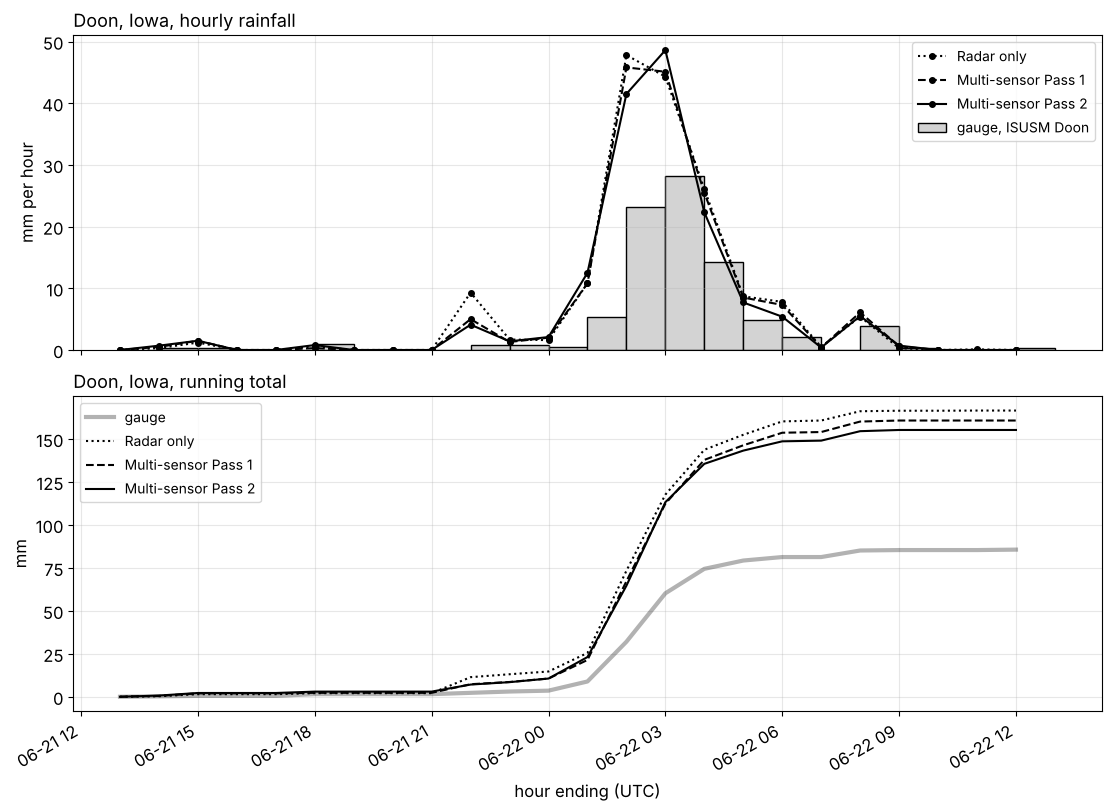

In [14]:
site = isusm_sites[isusm_sites.station == "DONI4"].iloc[0]
gauge_series = isusm[isusm.station == "DONI4"].set_index("valid_time").mm

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True, layout="constrained")
axes[0].bar(gauge_series.index, gauge_series.values, width=1 / 24, align="edge", color="lightgray",
            edgecolor="black", label="gauge, ISUSM Doon")
axes[1].plot(gauge_series.index, gauge_series.cumsum(), color="black", linewidth=3, alpha=0.3, label="gauge")
for p in PRODUCTS:
    s = point_series(hourly[p], site.lon, site.lat)                    # nearest grid cell, 24 values
    s.index = s.index.tz_localize("UTC")
    axes[0].plot(s.index, s.values, marker="o", markersize=4, label=LABELS[p], **STYLE[p])
    axes[1].plot(s.index, s.cumsum(), label=LABELS[p], **STYLE[p])
axes[0].set_ylabel("mm per hour"); axes[0].set_title("Doon, Iowa, hourly rainfall", loc="left")
axes[1].set_ylabel("mm"); axes[1].set_title("Doon, Iowa, running total", loc="left")
axes[1].set_xlabel("hour ending (UTC)")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend(fontsize=10)
fig.autofmt_xdate()
plt.show()

The timing agrees to the hour. The amounts do not. In the two heaviest hours the products show almost twice the gauge, and the storm total ends near 155 mm against 86 mm in the bucket. Three explanations are possible and they are not exclusive.

- Hail in the convective core inflates radar reflectivity, and the gauge correction is a smooth field that cannot remove a 1 km spot.
- A tipping bucket under-catches at intensities near 50 mm per hour, though rarely by half.
- The true maximum fell between gauges. The nearest volunteer gauges, Rock Rapids 5.6 W (118 mm) and Sioux Center 2.6 N (80 mm), agree with the products within 10 to 20 percent.

One gauge cannot settle this. Many gauges can, which is the point of the next two sections.

### 5b. All hourly stations, 24 h totals

Before scoring, one more quality rule. Several airports report a few millimetres under a radar total of 60 to 140 mm. MRMS applies the same kind of consistency check and rejects such gauges before using them. We flag them and leave them out of the scores.

One point per station. The closer to the diagonal, the better. Three scores summarise each panel, the bias ratio (product total divided by gauge total), the root mean square error and the correlation.

flagged as suspect sensors: ['YKN', 'SHL', 'BKX', 'ULM', 'SXK', 'MWM']


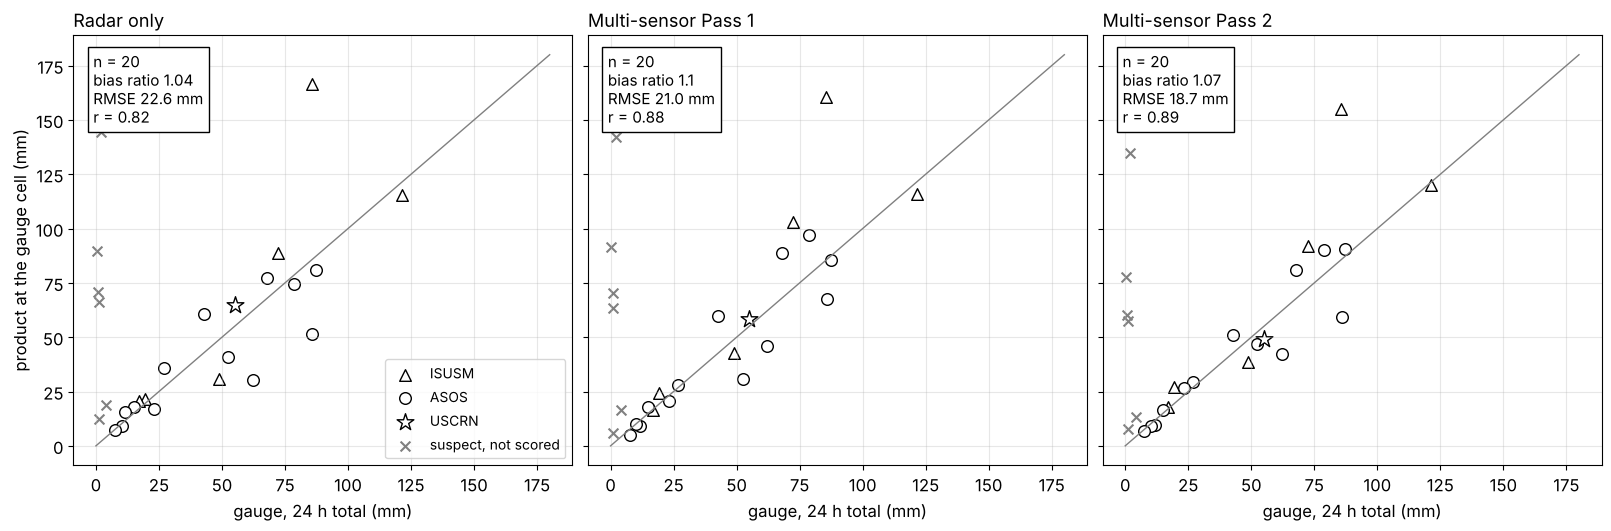

In [15]:
def product_at_stations(field, stations):
    """Value of a 2-D field at the grid cell of each station."""
    return [float(field.sel(lon=r.lon, lat=r.lat, method="nearest")) for r in stations.itertuples()]

for p in PRODUCTS:
    totals[p] = product_at_stations(total[p], totals)

# Flag an airport when its total is below one quarter of the radar only total at its cell.
totals["suspect"] = (totals.network == "ASOS") & (totals.total_mm < 0.25 * totals.RadarOnly) & (totals.RadarOnly > 10)
print("flagged as suspect sensors:", totals[totals.suspect].station.tolist())
good = totals[~totals.suspect]

markers = {"ISUSM": "^", "ASOS": "o", "USCRN": "*"}
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), sharex=True, sharey=True, layout="constrained")
for ax, p in zip(axes, PRODUCTS):
    for net, m in markers.items():
        d = good[good.network == net]
        ax.scatter(d.total_mm, d[p], marker=m, s=70 if net != "USCRN" else 160, facecolor="white",
                   edgecolor="black", label=net)
    bad = totals[totals.suspect]
    ax.scatter(bad.total_mm, bad[p], marker="x", s=50, color="gray", label="suspect, not scored")
    sc = score(good.total_mm, good[p])
    ax.plot([0, 180], [0, 180], color="gray", linewidth=1)
    ax.set_title(LABELS[p], loc="left")
    ax.text(0.04, 0.96, f"n = {sc['n']}\nbias ratio {sc['bias_ratio']}\nRMSE {sc['rmse_mm']} mm\nr = {sc['correlation']}",
            transform=ax.transAxes, va="top", fontsize=11, bbox=dict(facecolor="white", edgecolor="black"))
    ax.set_xlabel("gauge, 24 h total (mm)"); ax.grid(alpha=0.3)
axes[0].set_ylabel("product at the gauge cell (mm)"); axes[0].legend(loc="lower right", fontsize=10)
plt.show()

A caution. Airport and HADS gauges are among the gauges MRMS uses for its correction, so Pass 2 is partly being compared to itself here. The next section uses gauges that MRMS never sees.

## 6. Independent check with CoCoRaHS

Volunteers read their gauge near 7 am local time, 12 UTC in June. Their June 22 report covers almost exactly our 24 hours, and NSSL does not use these reports in the hourly correction. We take the reports from the three states in the box.

In [16]:
cocorahs = load_or_fetch("cocorahs_20240622.csv",
                         lambda: pd.concat([iem_cocorahs_daily(n, "2024-06-22")
                                            for n in ["IA_COCORAHS", "SD_COCORAHS", "MN_COCORAHS"]]))
west, east, south, north = EVENT_BOX
cocorahs = cocorahs[(cocorahs.lon.between(west, east)) & (cocorahs.lat.between(south, north))].reset_index(drop=True)
for p in PRODUCTS:
    cocorahs[p] = product_at_stations(total[p], cocorahs)
print(len(cocorahs), "reports in the box, largest", cocorahs.mm.max().round(1), "mm at", cocorahs.loc[cocorahs.mm.idxmax(), "name"])

144 reports in the box, largest 145.3 mm at Milford 1.4 NNE


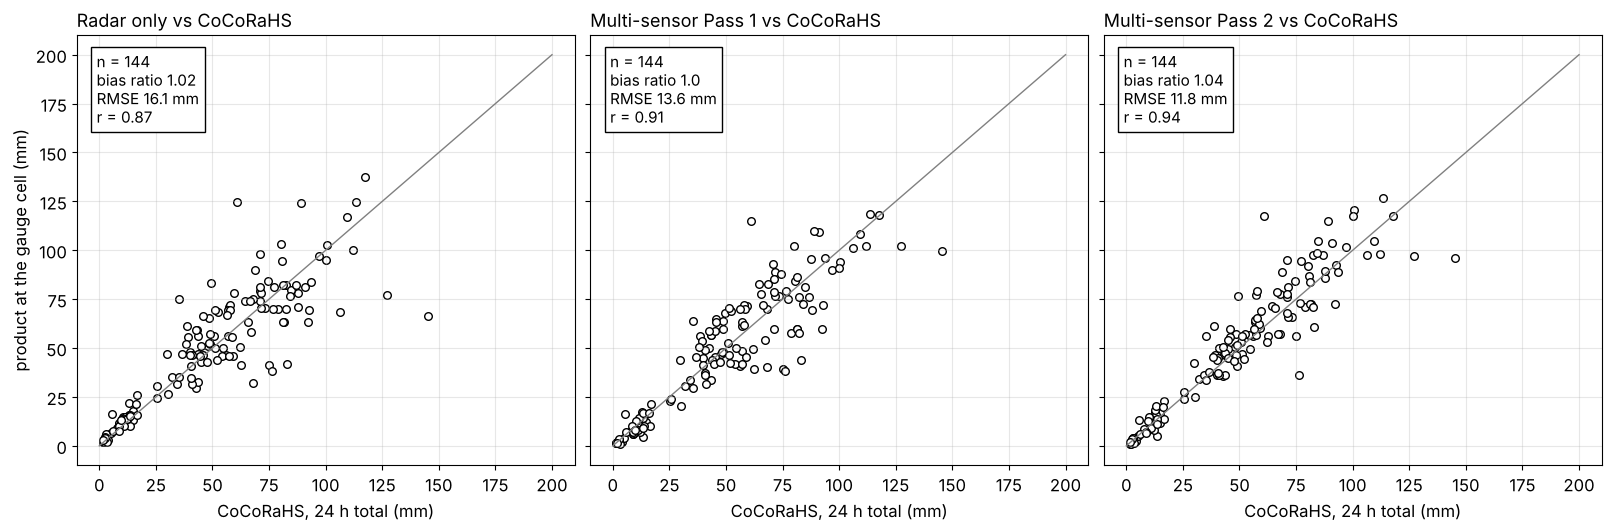

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), sharex=True, sharey=True, layout="constrained")
for ax, p in zip(axes, PRODUCTS):
    ax.scatter(cocorahs.mm, cocorahs[p], s=30, facecolor="white", edgecolor="black")
    sc = score(cocorahs.mm, cocorahs[p])
    ax.plot([0, 200], [0, 200], color="gray", linewidth=1)
    ax.set_title(f"{LABELS[p]} vs CoCoRaHS", loc="left")
    ax.text(0.04, 0.96, f"n = {sc['n']}\nbias ratio {sc['bias_ratio']}\nRMSE {sc['rmse_mm']} mm\nr = {sc['correlation']}",
            transform=ax.transAxes, va="top", fontsize=11, bbox=dict(facecolor="white", edgecolor="black"))
    ax.set_xlabel("CoCoRaHS, 24 h total (mm)"); ax.grid(alpha=0.3)
axes[0].set_ylabel("product at the gauge cell (mm)")
plt.show()

Questions for the group

1. Which product has the bias ratio closest to 1, and which the smallest RMSE?
2. Is the improvement from radar only to Pass 1 larger or smaller than the improvement from Pass 1 to Pass 2?
3. Part of the scatter is not product error at all. A 4 inch gauge samples a few square centimetres, the grid cell is one square kilometre. How would you separate the two?

## 7. Rainfall over a river basin, the input of Module 2

A flash flood model does not use a map, it uses the rain that fell inside each basin. We take the Floyd River basin at Alton from the USGS NLDI service, mask the grid cells inside it and average them hour by hour.

767 grid cells inside the basin


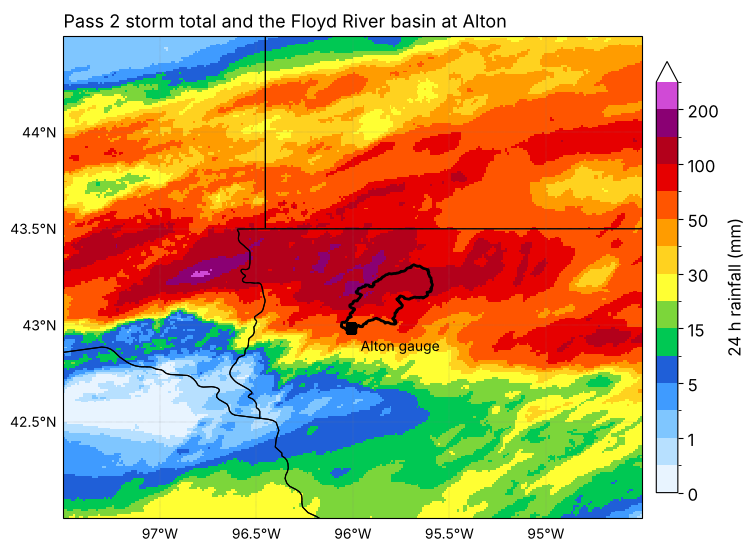

In [18]:
basin = nldi_basin("06600100")                               # Floyd River at Alton, Iowa, 694 square km
mask = basin_mask(total["Pass2"], basin)
print(f"{int(mask.sum())} grid cells inside the basin")

fig = plt.figure(figsize=(9, 7))
ax = plt.axes(projection=ccrs.PlateCarree())
mesh = rain_map(total["Pass2"], EVENT_BOX, "Pass 2 storm total and the Floyd River basin at Alton", ax=ax)
ax.plot(*basin.exterior.xy, color="black", linewidth=2, transform=ccrs.PlateCarree())
ax.plot(*ALTON, marker="s", color="black", markersize=7, transform=ccrs.PlateCarree())
ax.text(ALTON[0] + 0.05, ALTON[1] - 0.12, "Alton gauge", fontsize=10)
fig.colorbar(mesh, ax=ax, shrink=0.8, pad=0.02, label="24 h rainfall (mm)")
plt.show()

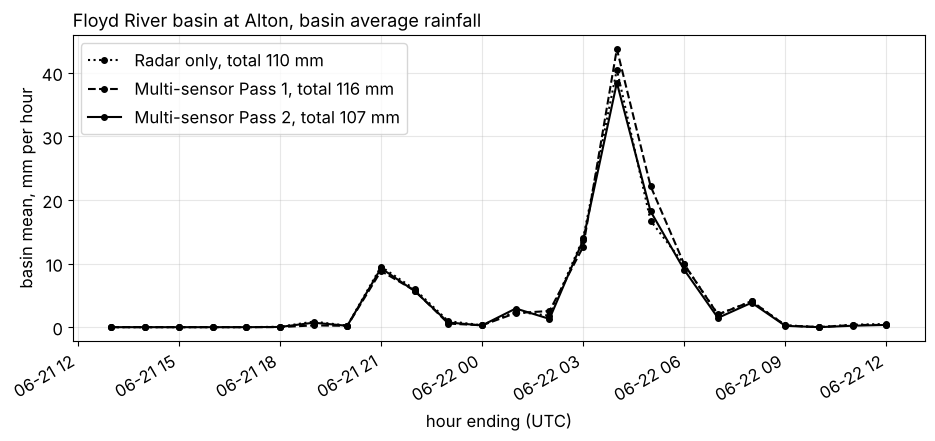

Radar only             total 110.5 mm   peak hour 40.5 mm at 04:00 UTC
Multi-sensor Pass 1    total 116.2 mm   peak hour 43.7 mm at 04:00 UTC
Multi-sensor Pass 2    total 106.6 mm   peak hour 38.4 mm at 04:00 UTC


In [19]:
basin_rain = {p: basin_mean_series(hourly[p], basin) for p in PRODUCTS}

fig, ax = plt.subplots(figsize=(11, 4.5))
for p in PRODUCTS:
    s = basin_rain[p]
    ax.plot(s.index, s.values, marker="o", markersize=4, label=f"{LABELS[p]}, total {s.sum():.0f} mm", **STYLE[p])
ax.set_ylabel("basin mean, mm per hour"); ax.set_xlabel("hour ending (UTC)")
ax.set_title("Floyd River basin at Alton, basin average rainfall", loc="left")
ax.legend(); ax.grid(alpha=0.3); fig.autofmt_xdate()
plt.show()

for p in PRODUCTS:
    s = basin_rain[p]
    print(f"{LABELS[p]:22s} total {s.sum():5.1f} mm   peak hour {s.max():4.1f} mm at {s.idxmax():%H:%M} UTC")

A few millimetres of difference on a basin of 694 square kilometres is a few million cubic metres of water. Module 2 shows what that does to the hydrograph.

## 8. Guided activity, the forecaster at 6 am

It is 06:30 UTC on June 22 (1:30 am CDT), half an hour before the Flash Flood Emergency. Which rainfall estimate exists at that moment?

From Notebook 1, section 4, the files reach the archive about

- Radar only, within a few minutes. The hour ending 06:00 is in.
- Pass 1, about 20 minutes after the hour. The hour ending 06:00 is in.
- Pass 2, about one hour after the hour. The latest complete hour is 05:00.

Compute the basin rainfall since the start of the window as each product showed it at 06:30, and compare it with what Pass 2 finally said for the same hours once all the files were in. Fill in the places marked with the comments.

In [20]:
# Activity, step 1. Define the decision time and the last available hour of each product.
# >>> SOLUTION
DECISION = pd.Timestamp("2024-06-22 06:30")
last_hour = {"RadarOnly": pd.Timestamp("2024-06-22 06:00"),
             "Pass1": pd.Timestamp("2024-06-22 06:00"),
             "Pass2": pd.Timestamp("2024-06-22 05:00")}
# <<< SOLUTION

In [21]:
# Activity, step 2. For each product, sum the basin mean rainfall over the hours available at the decision time.
#                   Use basin_rain[p] from section 7 and keep hours up to last_hour[p].
# >>> SOLUTION
known = {}
for p in PRODUCTS:
    s = basin_rain[p]
    known[p] = s[s.index <= last_hour[p]].sum()
    print(f"{LABELS[p]:22s} known at {DECISION:%H:%M} UTC: {known[p]:5.1f} mm through hour ending {last_hour[p]:%H:%M}")
# <<< SOLUTION

Radar only             known at 06:30 UTC: 103.2 mm through hour ending 06:00
Multi-sensor Pass 1    known at 06:30 UTC: 109.2 mm through hour ending 06:00
Multi-sensor Pass 2    known at 06:30 UTC:  91.5 mm through hour ending 05:00


In [22]:
# Activity, step 3. The answer in hindsight. Sum the final Pass 2 basin rainfall through 06:00
#                   and express each product's known total as a percent of it.
# >>> SOLUTION
final = basin_rain["Pass2"][basin_rain["Pass2"].index <= pd.Timestamp("2024-06-22 06:00")].sum()
print(f"final Pass 2 through 06:00 UTC: {final:.1f} mm")
for p in PRODUCTS:
    print(f"{LABELS[p]:22s} {100 * known[p] / final:5.0f} percent of the final amount")
# <<< SOLUTION

final Pass 2 through 06:00 UTC: 100.5 mm
Radar only               103 percent of the final amount
Multi-sensor Pass 1      109 percent of the final amount
Multi-sensor Pass 2       91 percent of the final amount


In [23]:
# Activity, step 4. Build the best estimate an analyst could assemble at 06:30,
#                   Pass 2 for the hours it covers, then Pass 1 for the hours after that.
#                   Hint: concatenate the two series after slicing them by time.
# >>> SOLUTION
best = pd.concat([basin_rain["Pass2"][basin_rain["Pass2"].index <= last_hour["Pass2"]],
                  basin_rain["Pass1"][(basin_rain["Pass1"].index > last_hour["Pass2"]) &
                                      (basin_rain["Pass1"].index <= last_hour["Pass1"])]])
print(f"blended estimate at 06:30 UTC: {best.sum():.1f} mm, that is {100 * best.sum() / final:.0f} percent of the final amount")
# <<< SOLUTION

blended estimate at 06:30 UTC: 101.4 mm, that is 101 percent of the final amount


Questions to close the module

1. How many millimetres of basin rainfall were still unknown at 06:30 UTC because of latency, and because of the missing gauge correction?
2. If a model needs the full rainfall to produce a warning, how much lead time does Pass 2 cost compared with radar only? Is it worth it?
3. Repeat the activity for the Rock River near Rock Valley (USGS 06483500). The basin is larger, 4,100 square kilometres. Does the conclusion change?

## References and credits

- Project Pythia MRMS Cookbook, Janoski, Sears, Condo, Heaton, Collins and Grover, CC BY 4.0. https://projectpythia.org/mrms-cookbook/
- Zhang, J. and coauthors, 2016. Multi-Radar Multi-Sensor (MRMS) Quantitative Precipitation Estimation, Initial Operating Capabilities. Bulletin of the American Meteorological Society, 97, 621 to 638. https://doi.org/10.1175/BAMS-D-14-00174.1
- NOAA NSSL, MRMS operational product tables, version 12.2. https://nssl.noaa.gov/projects/mrms/operational/tables.php
- Martinaitis, S. M., 2021. MRMS QPE and CoCoRaHS, WERA-1012 meeting. https://media.cocorahs.org/docs/Martinaitis-WERA21.pdf
- NWS Sioux Falls, Flash Flood Warning text for Rock Valley, June 22, 2024, 06:56 UTC, through the Iowa Environmental Mesonet archive.
- USGS National Water Information System, sites 06483500 and 06600100, and the Network Linked Data Index. https://waterdata.usgs.gov/
- Iowa Environmental Mesonet, web services. https://mesonet.agron.iastate.edu/
- NOAA NCEI, U.S. Climate Reference Network. https://www.ncei.noaa.gov/access/crn/